<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_26_Current_Layer%3DPrevious_layer_%2B_Adjustments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr,spearmanr

import torch

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Hooks and Hidden_State

## Task_1:
- Import GPT-2-small, implant the hook function shown above into
transformer layer 5, and tokenize the following text (it’s also printed
in the online code file): Plants make fantastic pets because they don’t
leave a mess after you feed them.
Call a forward pass and remove the hook.
Check that the shape of the tensor stored in the transf_out
dictionary matches that of the output of the hidden states. Pick
one embeddings dimension and make a scatter plot of the value in
that dimension for both the hidden state and the transformer output
(Figure 5.16). The data points should overlap because they both
access the same data.
After the visual confirmation for one embeddings dimension,
subtract the hidden-state tensor from the transformer output tensor,
and confirm that the difference matrix is all zeros.

In [2]:
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2',output_hidden_states=True)
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [3]:
# initialize the dictionary containing data
transf_out = {}

# the hook function
def hook(module, input, output):
  # module: the layer the hook is attached to
  # input : inputs passed into that layer during the forward pass
  # output: output of that layer
  transf_out['data'] = output.detach()

# implant the hook
layi = 5
handle = model.transformer.h[layi].register_forward_hook(hook)

In [4]:
model.transformer.h

ModuleList(
  (0-11): 12 x GPT2Block(
    (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (attn): GPT2Attention(
      (c_attn): Conv1D(nf=2304, nx=768)
      (c_proj): Conv1D(nf=768, nx=768)
      (attn_dropout): Dropout(p=0.1, inplace=False)
      (resid_dropout): Dropout(p=0.1, inplace=False)
    )
    (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (mlp): GPT2MLP(
      (c_fc): Conv1D(nf=3072, nx=768)
      (c_proj): Conv1D(nf=768, nx=3072)
      (act): NewGELUActivation()
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
)

In [5]:
model.transformer.h[5]

GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [6]:

text = "Plants make fantastic pets because they don't leave a mess after you feed them."
tokens = tokenizer.encode(text,return_tensors="pt")

# forward pass to trigger the hook
with torch.no_grad():
  outputs =model(tokens)

# remove the hook
handle.remove()

In [7]:
print('     Hidden states is size:',outputs.hidden_states[layi+1].shape)
print('Transformer output is size:',transf_out['data'].shape)

     Hidden states is size: torch.Size([1, 17, 768])
Transformer output is size: torch.Size([1, 17, 768])


In [8]:
outputs.hidden_states[6]

tensor([[[-0.0448, -2.6673, -0.8086,  ..., -0.4345, -1.0803, -0.4612],
         [-0.7582,  0.2152, -0.1291,  ...,  0.6818, -0.6248,  0.5173],
         [ 0.6731, -1.9390, -0.5297,  ...,  1.9940, -2.2004, -1.6972],
         ...,
         [ 0.3338, -1.8965, -5.4044,  ..., -4.9260, -1.0576, -1.8959],
         [-0.8103,  2.2054, -5.0447,  ...,  1.5602,  0.4215, -1.5921],
         [ 0.8897, -1.8465, -0.7044,  ..., -0.1974, -1.7365, -0.1480]]])

In [9]:
transf_out

{'data': tensor([[[-0.0448, -2.6673, -0.8086,  ..., -0.4345, -1.0803, -0.4612],
          [-0.7582,  0.2152, -0.1291,  ...,  0.6818, -0.6248,  0.5173],
          [ 0.6731, -1.9390, -0.5297,  ...,  1.9940, -2.2004, -1.6972],
          ...,
          [ 0.3338, -1.8965, -5.4044,  ..., -4.9260, -1.0576, -1.8959],
          [-0.8103,  2.2054, -5.0447,  ...,  1.5602,  0.4215, -1.5921],
          [ 0.8897, -1.8465, -0.7044,  ..., -0.1974, -1.7365, -0.1480]]])}

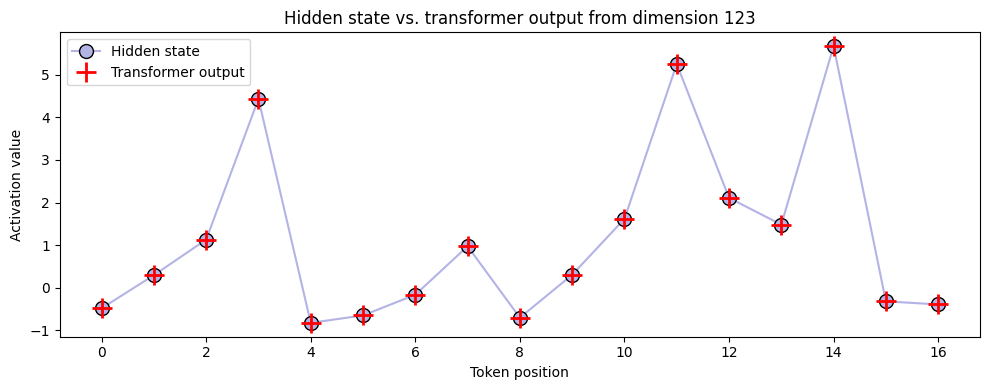

In [10]:
plt.figure(figsize=(10,4))

dimnum = 123

plt.plot(outputs.hidden_states[layi+1][0,:,dimnum],'o-',markeredgecolor='k',
         color=[.7,.7,.9],markerfacecolor=[.7,.7,.9],markersize=10,label='Hidden state')
plt.plot(transf_out['data'][0,:,dimnum],'r+',markersize=14,markeredgewidth=2,label='Transformer output')

plt.gca().set(xlabel='Token position',ylabel='Activation value',title=f'Hidden state vs. transformer output from dimension {dimnum}')
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# differences are zeros
outputs.hidden_states[layi+1] - transf_out['data']

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]])

# Part_2:Final_Hidden_layer_Normalization

## Task_1:
- Run the hook-generating code block and call the model forward pass
again. Then remove all the hooks. Check the keys of the transf_out
dictionary, and the size of the data stored in one of the items.
In a for-loop over all layers, subtract the hooked transformer
outputs from the corresponding hidden-state tensor, and store the
norm of that difference matrix. Show the results in a scatter plot
as in Figure 5.17. Matrix difference norms of zero indicate that the
hidden states and hooked transformer outputs are identical.
Find the final layerNorm layer in the transformer module (hint: “lay
erNorm final” is abbreviated to ln_f) and apply that transformation
to the final hooked transformer output. Then subtract that result
from the final hidden states tensor and confirm that their difference
matrix is all zeros.

In [12]:
model.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "output_hidden_states": true,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.22.1",
  "use_cache": true,
  "vocab_size": 5025

In [13]:
n_layers=model.config.n_layer

In [14]:
transf_out={}
def outerHook(layeri):
  def hook(module, input, output):
    transf_out[f'layer_{layeri}'] =output.detach()
  return hook
handles = []
for layeri in range(model.config.n_layer):
  modname = model.transformer.h[layeri]
  h = modname.register_forward_hook(outerHook(layeri))
  handles.append(h)

In [15]:

# forward pass to trigger the hook
with torch.no_grad():
  outputs = model(tokens)

# remove the hooks
for h in handles:
  h.remove()

In [16]:

print('Here are the keys in transf_out:\n ',transf_out.keys(),'\n')
print("transf_out['layer_3'] has size:\n ",transf_out['layer_3'].shape)

Here are the keys in transf_out:
  dict_keys(['layer_0', 'layer_1', 'layer_2', 'layer_3', 'layer_4', 'layer_5', 'layer_6', 'layer_7', 'layer_8', 'layer_9', 'layer_10', 'layer_11']) 

transf_out['layer_3'] has size:
  torch.Size([1, 17, 768])


In [17]:
# initialize
norms = torch.zeros(n_layers)

# loop over layers
for i in range(n_layers):
  diffmat = outputs.hidden_states[i+1] - transf_out[f'layer_{i}']
  norms[i] = torch.norm(diffmat)

In [18]:
diffmat

tensor([[[ 1.1447,  1.0964,  1.6725,  ...,  0.5051,  0.6774,  0.5622],
         [ 2.4622, -1.6849,  3.2337,  ..., -5.1206,  2.1915, -2.8593],
         [ 4.5681, -1.8661,  7.3715,  ..., -2.8903, 10.0386,  5.5353],
         ...,
         [ 5.8281, -0.5633, 17.1717,  ...,  8.1869,  5.1724, -0.0557],
         [ 3.1437,  1.5837, 18.4548,  ..., -2.9166,  6.1999,  1.3538],
         [ 3.4116,  0.3261, -3.3490,  ..., -0.5914,  6.9533,  0.0968]]])

In [19]:
torch.norm(diffmat,dim=0)

tensor([[ 1.1447,  1.0964,  1.6725,  ...,  0.5051,  0.6774,  0.5622],
        [ 2.4622,  1.6849,  3.2337,  ...,  5.1206,  2.1915,  2.8593],
        [ 4.5681,  1.8661,  7.3715,  ...,  2.8903, 10.0386,  5.5353],
        ...,
        [ 5.8281,  0.5633, 17.1717,  ...,  8.1869,  5.1724,  0.0557],
        [ 3.1437,  1.5837, 18.4548,  ...,  2.9166,  6.1999,  1.3538],
        [ 3.4116,  0.3261,  3.3490,  ...,  0.5914,  6.9533,  0.0968]])

In [20]:
norms

tensor([   0.0000,    0.0000,    0.0000,    0.0000,    0.0000,    0.0000,
           0.0000,    0.0000,    0.0000,    0.0000,    0.0000, 1495.6089])

In [21]:
outputs.hidden_states[12]

tensor([[[-1.9451e-01, -1.4564e-01, -4.4502e-01,  ..., -1.0212e-01,
          -1.3449e-01, -6.8415e-02],
         [-2.8688e-01,  2.3189e-01, -6.1044e-01,  ...,  4.4732e-01,
          -2.2456e-01,  3.1965e-01],
         [-4.2464e-01,  2.1577e-01, -1.0389e+00,  ...,  2.0233e-01,
          -7.5159e-01, -4.0360e-01],
         ...,
         [-5.1509e-01,  1.1283e-01, -2.2597e+00,  ..., -5.7964e-01,
          -3.7854e-01,  6.0511e-02],
         [-3.0081e-01, -1.0369e-01, -2.6378e+00,  ...,  2.2330e-01,
          -4.9454e-01, -6.7813e-02],
         [-2.8698e-01,  1.9229e-03,  2.8597e-01,  ...,  1.7350e-02,
          -4.7139e-01,  2.0093e-02]]])

In [22]:
transf_out[f'layer_{11}']

tensor([[[ -1.3392,  -1.2421,  -2.1175,  ...,  -0.6072,  -0.8119,  -0.6307],
         [ -2.7491,   1.9168,  -3.8442,  ...,   5.5679,  -2.4161,   3.1790],
         [ -4.9927,   2.0818,  -8.4105,  ...,   3.0926, -10.7902,  -5.9390],
         ...,
         [ -6.3431,   0.6761, -19.4314,  ...,  -8.7666,  -5.5510,   0.1162],
         [ -3.4445,  -1.6874, -21.0926,  ...,   3.1399,  -6.6944,  -1.4217],
         [ -3.6986,  -0.3241,   3.6350,  ...,   0.6087,  -7.4247,  -0.0767]]])

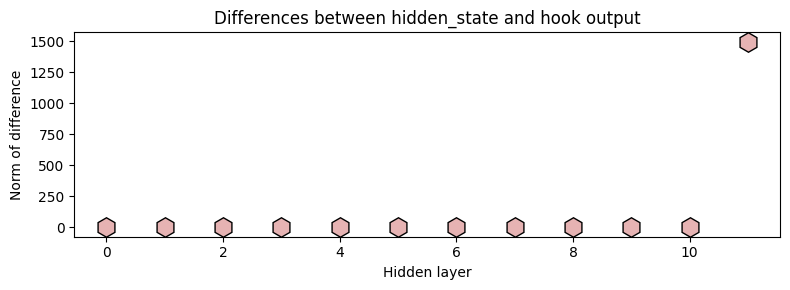

In [23]:
plt.figure(figsize=(8,3))
plt.plot(norms,'kh',markerfacecolor=[.9,.7,.7],markersize=14)
plt.gca().set(xlabel='Hidden layer',ylabel='Norm of difference',
              title='Differences between hidden_state and hook output')

plt.tight_layout()
plt.show()

In [24]:
lastL = model.config.n_layer - 1

layerNorm_final = model.transformer.ln_f( transf_out[f'layer_{lastL}'] )
outputs.hidden_states[lastL+1] - layerNorm_final

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]], grad_fn=<SubBackward0>)

In [25]:
lastL

11

In [26]:
model.transformer.ln_f(transf_out[f'layer_{11}'])

tensor([[[-1.9451e-01, -1.4564e-01, -4.4502e-01,  ..., -1.0212e-01,
          -1.3449e-01, -6.8415e-02],
         [-2.8688e-01,  2.3189e-01, -6.1044e-01,  ...,  4.4732e-01,
          -2.2456e-01,  3.1965e-01],
         [-4.2464e-01,  2.1577e-01, -1.0389e+00,  ...,  2.0233e-01,
          -7.5159e-01, -4.0360e-01],
         ...,
         [-5.1509e-01,  1.1283e-01, -2.2597e+00,  ..., -5.7964e-01,
          -3.7854e-01,  6.0511e-02],
         [-3.0081e-01, -1.0369e-01, -2.6378e+00,  ...,  2.2330e-01,
          -4.9454e-01, -6.7813e-02],
         [-2.8698e-01,  1.9229e-03,  2.8597e-01,  ...,  1.7350e-02,
          -4.7139e-01,  2.0093e-02]]], grad_fn=<NativeLayerNormBackward0>)

# Part 3: Hooking attention and MLP adjustments


## Task_1:
- Write two hook functions to grab the projections from the attention
and MLP blocks. Pick one layer to implant into (I used transformer
layer 10). There are several modules within the attention block;
implant the hooks into the output projections attn.c_proj and
mlp.c_proj. These are the “projections” (the adjustments to
the hidden-state vectors) after the internal calculations have been
completed.
Do not assign an output to the register_forward_hook func
tion. That has no implications for the functioning of the hook, but it
prevents you from being able to remove the hook once it’s attached.
This will be relevant later in the project.
Run a forward pass to trigger the two hook functions and check the
sizes of the activations matrices

In [27]:
# re-initialize activations dictionary
activations = {}

# into attention projections
def hook_att(module, input, output):
  activations['attn'] =output.detach()

# and into mlp projections
def hook_mlp(module, input, output):
  activations['mlp'] =output.detach()


# implant hooks into projection layers
layer2hook = 10

model.transformer.h[layer2hook].attn.c_proj .register_forward_hook(hook_att)
model.transformer.h[layer2hook]. mlp.c_proj.register_forward_hook(hook_mlp)

In [30]:
# forward pass to trigger the hook
with torch.no_grad():
  outputs = model(tokens)

print('Here are the keys in "activations":\n ',activations.keys(),'\n')
print("activations['attn'] has size:\n ",activations['attn'].shape,'\n')
print("activations['mlp'] has size:\n ",activations['mlp'].shape)

Here are the keys in "activations":
  dict_keys(['attn', 'mlp']) 

activations['attn'] has size:
  torch.Size([1, 17, 768]) 

activations['mlp'] has size:
  torch.Size([1, 17, 768])


## Task_2
- In a for-loop over the tokens in the sequence, calculate the correla
tion coefficient between the attention and MLP adjustment vectors.
Calculate the correlation twice: using the Pearson correlation and
using the Spearman correlation. You can get those two correlation
functions from the scipy.stats library.
Show the resulting token sequence of correlation coefficients in
a scatter plot as in Figure 5.18A. Then show a scatter plot of those
adjustments for one token as in Figure 5.18B (I plotted the final
token)

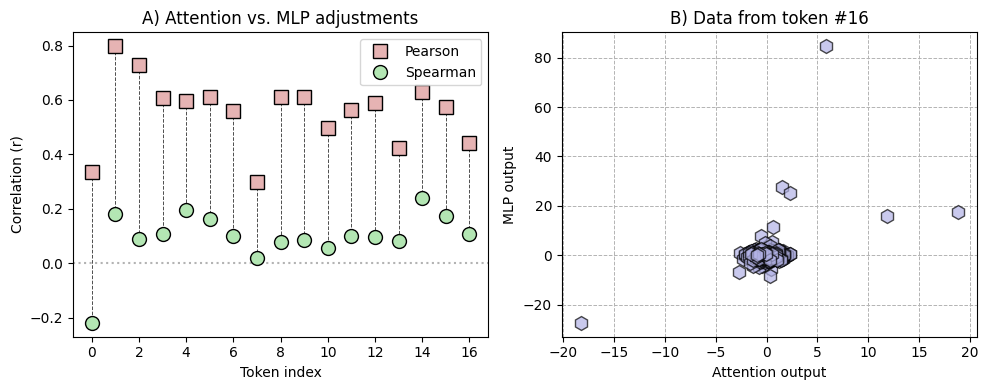

In [31]:
_,axs = plt.subplots(1,2,figsize=(10,4))


# loop over tokens
for toki in range(len(tokens[0])):

  # extract vectors
  a = activations['attn'][0,toki,:]
  m = activations['mlp'][0,toki,:]

  # correlate them
  r_p = pearsonr(a,m).statistic
  r_s = spearmanr(a,m).statistic

  # plot them
  axs[0].plot(toki,r_p,'ks',markerfacecolor=[.9,.7,.7],markersize=10)
  axs[0].plot(toki,r_s,'ko',markerfacecolor=[.7,.9,.7],markersize=10)
  axs[0].plot([toki,toki],[r_p,r_s],'--',color=[.3,.3,.3],linewidth=.7,zorder=-10)


axs[0].legend(['Pearson','Spearman'])
axs[0].axhline(0,linestyle=':',color=[.7,.7,.7],zorder=-20)
axs[0].set(xlabel='Token index',ylabel='Correlation (r)',
           title='A) Attention vs. MLP adjustments')


axs[1].plot(a,m,'kh',markerfacecolor=[.7,.7,.9,.7],markersize=10)
axs[1].grid(linestyle='--',color=[.7,.7,.7],linewidth=.7)
axs[1].set(xlabel='Attention output',ylabel='MLP output',
           title=f'B) Data from token #{toki}')

plt.tight_layout()
plt.show()

# Part_4:Reconstructing Hidden state L From L-1

## Task_1
- Using the hidden states and hooked attention and MLP activations
that you obtained in Part 3, reconstruct the hidden-state vectors
from one layer based on vectors from the previous layer plus the
adjustments, by translating the following equation into code:
HSL = HSL−1 +attnL +MLPL
Demonstrate the reconstruction accuracy by subtracting the vari
ables for the two sides of the equation, and evaluating whether the
norm of the difference vector is zero (within precision-error tolerance).
Then visualize the results as in Figure 5.19.
Note: This equation is accurate in terms of code implementa
tion but oversimplifies the actual calculations. I’ll get back to this
after discussing the results.

In [39]:
hs_pre = outputs.hidden_states[layer2hook]
hs_pst = outputs.hidden_states[layer2hook+1]

# reconstruct one layer from the previous
recon =hs_pre + activations['attn']+ activations['mlp']

print('  Attention size:', activations['attn'].shape)
print('        MLP size:', activations['mlp'].shape)
print('Hidden state pre:', hs_pre.shape)
print('Hidden state pst:', hs_pst.shape)

  Attention size: torch.Size([1, 17, 768])
        MLP size: torch.Size([1, 17, 768])
Hidden state pre: torch.Size([1, 17, 768])
Hidden state pst: torch.Size([1, 17, 768])


In [46]:
# demonstrate the reconstruction accuracy
recon-hs_pst, torch.norm(recon-hs_pst)

(tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]]),
 tensor(0.))

In [47]:

# common axis limits
ax_lim = max( torch.max(torch.abs(hs_pre[0,1:,:])).item(),
              torch.max(torch.abs(hs_pst[0,1:,:])).item() )

# increase a bit for marker size
ax_lim *= 1.1

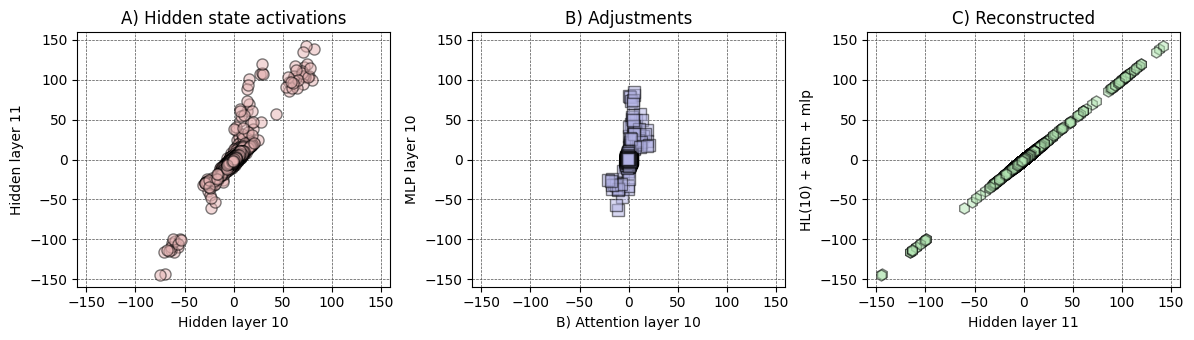

In [48]:

_,axs = plt.subplots(1,3,figsize=(12,3.5))

axs[0].plot(hs_pre[0,1:,:].flatten(),hs_pst[0,1:,:].flatten(),'ko',markerfacecolor=[.9,.7,.7,.5],markersize=8)
axs[0].set(xlabel=f'Hidden layer {layer2hook}',ylabel=f'Hidden layer {layer2hook+1}',
           title='A) Hidden state activations',xlim=[-ax_lim,ax_lim],ylim=[-ax_lim,ax_lim])

axs[1].plot(activations['attn'][0,1:,:].flatten(),activations['mlp'][0,1:,:].flatten(),'ks',markerfacecolor=[.7,.7,.9,.5],markersize=8)
axs[1].set(xlabel=f'B) Attention layer {layer2hook}',ylabel=f'MLP layer {layer2hook}',title='B) Adjustments',
           xlim=[-ax_lim,ax_lim],ylim=[-ax_lim,ax_lim])

axs[2].plot(hs_pst[0,1:,:].flatten(),recon[0,1:,:].flatten(),'kh',markerfacecolor=[.7,.9,.7,.5],markersize=8)
axs[2].set(xlabel=f'Hidden layer {layer2hook+1}',ylabel=f'HL({layer2hook}) + attn + mlp',title='C) Reconstructed',
           xlim=[-ax_lim,ax_lim],ylim=[-ax_lim,ax_lim])

for a in axs:
  a.grid(linestyle='--',color=[.3,.3,.3],linewidth=.5)


plt.tight_layout()
plt.show()